# Sesión experimental: desafiar las hipótesis del dataset

Este notebook responde a las ocho ideas de README.md. No modifica ese archivo ni experimentos previos.
Una AUC ~0.63 no permite saber cuánto margen de mejora existe: puede reflejar información limitada,
ruido del generador o formulación. Distinguimos evidencia predictiva, plausibilidad y artefactos.

**Protocolo mensual:** selección agosto-octubre; noviembre como comprobación posterior con decisión
congelada. Noviembre ya fue explorado en el proyecto, por lo que no es un holdout virgen. Parámetros
fijos, sin early stopping ni tuning del mes evaluado. No se lee test ni se genera una nueva entrega.
Los experimentos de conversión acumulada usan otra etiqueta: sus AUC no se comparan con las mensuales.

**Supuesto operativo:** covariables disponibles antes del evento y etiquetas del mes previo disponibles
al siguiente origen. Las pruebas del código no certifican timestamps de origen ausentes en el CSV.

In [2]:
from pathlib import Path
import os
import sys
import json
import time
import hashlib
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score, mean_absolute_error
from threadpoolctl import threadpool_limits

HERE=Path.cwd() if (Path.cwd()/'experimentos.py').exists() else Path.cwd()/'nuevas-tareas'
ROOT=HERE.parent
sys.path.insert(0,str(HERE))
from experimentos import (features,audits,SPECS,fit_month,survival_cox,scores,
                         cat_model,make_horizon,SEED)
threads=threadpool_limits(limits=4)
OUT=HERE/'resultados'
OUT.mkdir(exist_ok=True)
sns.set_theme(style='whitegrid',palette='colorblind')
pd.set_option('display.max_columns',25)
pd.set_option('display.max_colwidth',100)
plt.rcParams.update({'figure.dpi':110,'axes.titleweight':'bold'})
raw=pd.read_csv(ROOT/'train.csv')
d,groups=features(raw)
display(pd.DataFrame({'prueba':audits(raw)}))
print('Python',sys.version)
print('Datos:',len(raw),'filas;',raw.id_cliente.nunique(),'clientes')

,prueba
0,Features invariantes al truncar futuro: OK
1,Features independientes de etiquetas: OK
2,Horizontes maduros antes del origen de entrenamiento: OK
3,Features finitas: OK


Python 3.13.7 (tags/v3.13.7:bcee1c3, Aug 14 2025, 14:15:11) [MSC v.1944 64 bit (AMD64)]
Datos: 110100 filas; 24628 clientes


## 1. Plan de experimentos y decisiones previas

“Éxito”, gasto o ahorro no se observan. Usamos nombres neutrales para proxies de ingreso/edad y
cruces ingreso/dispositivo/préstamo. Una mejora no validaría el estereotipo de quien usa iOS o Android.
Los dos cambios forzados de tarjeta son intervenciones contrafactuales para medir daño/beneficio;
no constituyen una limpieza de datos ni certifican qué valor es verdadero.

In [3]:
plan=pd.DataFrame([
    ('Conversión sin cuándo','Evento observado hasta noviembre, una fila por cliente; controles de cohorte y horizonte','Diagnóstico retrospectivo; no etiqueta de nunca-conversión'),
    ('Ingreso/edad','Tres ratios o transformaciones determinísticas','Proxies cuantitativos, no éxito personal'),
    ('Ingreso/dispositivo','Seis cruces con bandas de ingreso, préstamo y deuda','No se interpreta como gasto, estatus o ahorro'),
    ('Foto de entrada','Añadir relojes mensual y anual de antigüedad, edad y recencia inicial','Recencia solo crece bajo el supuesto adicional de ningún evento nuevo'),
    ('Oversampling','Duplicación aleatoria y SMOTENC sobre perfil; antes/después de corrección de prior','Solo entrenamiento de cada corte; nunca sintéticos en evaluación'),
    ('Historia inventada','Cuantificar expansión/contradicciones; no entrenar como si fueran observaciones reales','Completar solo conversores depende del desenlace; falta historia previa verificable'),
    ('Cuándo convierte','Cox con censura + clasificación multiclase a tres meses','Tiempos desde primera observación; no desde apertura; no inferir nunca'),
    ('Periodo = año','Proxies de reloj anual + pruebas de consistencia','Renombrar el reloj no hace que los atributos congelados evolucionen'),
    ('Tarjeta sin uso','Cruces tarjeta-recencia y dos alteraciones artificiales','Transacción es de cuenta/cliente, no necesariamente de tarjeta'),
],columns=['idea','experimento','precaución'])
display(plan)
plan.to_csv(OUT/'plan.csv',index=False)
display(pd.DataFrame(SPECS).T)
print('Historial control:',len(groups['historia']),'features; perfil:',len(groups['perfil']))

,idea,experimento,precaución
0,Conversión sin cuándo,"Evento observado hasta noviembre, una fila por cliente; controles de cohorte y horizonte",Diagnóstico retrospectivo; no etiqueta de nunca-conversión
1,Ingreso/edad,Tres ratios o transformaciones determinísticas,"Proxies cuantitativos, no éxito personal"
2,Ingreso/dispositivo,"Seis cruces con bandas de ingreso, préstamo y deuda","No se interpreta como gasto, estatus o ahorro"
3,Foto de entrada,"Añadir relojes mensual y anual de antigüedad, edad y recencia inicial",Recencia solo crece bajo el supuesto adicional de ningún evento nuevo
4,Oversampling,Duplicación aleatoria y SMOTENC sobre perfil; antes/después de corrección de prior,Solo entrenamiento de cada corte; nunca sintéticos en evaluación
5,Historia inventada,Cuantificar expansión/contradicciones; no entrenar como si fueran observaciones reales,Completar solo conversores depende del desenlace; falta historia previa verificable
6,Cuándo convierte,Cox con censura + clasificación multiclase a tres meses,Tiempos desde primera observación; no desde apertura; no inferir nunca
7,Periodo = año,Proxies de reloj anual + pruebas de consistencia,Renombrar el reloj no hace que los atributos congelados evolucionen
8,Tarjeta sin uso,Cruces tarjeta-recencia y dos alteraciones artificiales,"Transacción es de cuenta/cliente, no necesariamente de tarjeta"


,group,intervention,sampling
Perfil_control,perfil,NaN,NaN
Historia_control,historia,NaN,NaN
Edad_ingreso,edad_ingreso,NaN,NaN
Dispositivo_ingreso,dispositivo,NaN,NaN
Ambos_perfiles,perfiles,NaN,NaN
Foto_entrada_mes,reloj_mes,NaN,NaN
Foto_entrada_anio,reloj_anio,NaN,NaN
Sin_interaccion,sin_interaccion,NaN,NaN
Tarjeta_recencia,tarjeta,NaN,NaN
Forzar_tarjeta_false,historia,flag,NaN


Historial control: 33 features; perfil: 22


## 2. ¿Qué implicaría inventar historia o cambiar el reloj?

Conteos descriptivos por cliente. Historial anterior a la entrada no está observado. Si se conoce el
desenlace para decidir a quién añadir filas, el proceso de selección usa el futuro de esas filas.
Además, la foto de entrada no prueba que las covariables existieran ni fueran iguales antes.
Evaluarlo en un mes futuro no convierte esos registros fabricados en observaciones point-in-time.

In [4]:
person=d.groupby('id_cliente').agg(entrada=('mes_ordinal','min'),fin=('mes_ordinal','max'),
    n=('mes','size'),evento=('objetivo','max'),cuenta=('antiguedad_cuenta_meses','first'),edad=('edad','first'))
person['faltantes_preentrada']=person.entrada-1
person['span']=person.fin-person.entrada
fake_all=int(person.faltantes_preentrada.sum())
fake_events=int(person.loc[person.evento.eq(1),'faltantes_preentrada'].sum())
diagnosis=pd.Series({
    'filas reales train':len(d),
    'filas cero inventadas para todos los entrantes':fake_all,
    'filas cero inventadas solo para futuros conversores':fake_events,
    'tasa real fila-mes':d.objetivo.mean(),
    'tasa si se agregaran ceros solo a conversores':d.objetivo.sum()/(len(d)+fake_events),
    'entrantes cuya cuenta no permite volver a enero (margen 1 mes)':int((person.cuenta<person.faltantes_preentrada-1).sum()),
    'snapshot final imposible reloj mensual (margen 1 mes)':int((person.cuenta<person.span-1).sum()),
    'snapshot final imposible reloj anual (margen 12 meses)':int((person.cuenta<12*(person.span-1)).sum()),
},name='valor')
display(diagnosis.to_frame())
diagnosis.to_csv(OUT/'diagnostico_historia_relojes.csv')
# Diferencia entre estar registrado y haber usado una tarjeta.
unique=d.drop_duplicates('id_cliente')
card_summary=unique.groupby('tiene_tarjeta_credito').agg(clientes=('id_cliente','size'),
    recencia_media=('dias_ultima_transaccion','mean'),
    proporcion_mas180=('dias_ultima_transaccion',lambda s:s.gt(180).mean()))
display(card_summary)
card_summary.to_csv(OUT/'tarjeta_recencia_descriptivo.csv')

,valor
filas reales train,110100.000000
filas cero inventadas para todos los entrantes,77279.000000
filas cero inventadas solo para futuros conversores,37593.000000
tasa real fila-mes,0.150472
tasa si se agregaran ceros solo a conversores,0.112172
entrantes cuya cuenta no permite volver a enero (margen 1 mes),257.000000
snapshot final imposible reloj mensual (margen 1 mes),284.000000
snapshot final imposible reloj anual (margen 12 meses),4380.000000


,clientes,recencia_media,proporcion_mas180
tiene_tarjeta_credito,,,
0,6096,182.880577,0.500000
1,18532,182.651576,0.505828


## 3. Trece variantes mensuales y supervivencia con censura

CatBoost comparte profundidad 5, 300 árboles y regularización. Se repiten los mismos cortes.
SMOTENC escala numéricas solo con train, preserva categorías/booleanos y redondea contadores.
Se muestran sus scores brutos y corregidos por prior: corregir odds no cambia AUC, sí calibración.
Para SMOTE es solo aproximación: el muestreo también puede cambiar distribuciones condicionadas.

**Cox:** una trayectoria por persona; evento si convirtió antes del corte, censura administrativa en
otro caso. Los tiempos son meses desde primera observación; hay truncamiento previo desconocido.
Se usa perfil de entrada, Breslow para empates y hazard del siguiente intervalo. Para exposiciones
mayores a las observadas en train se extrapola el promedio de los últimos tres incrementos basales.
La aproximación continua y riesgos proporcionales son supuestos, no hechos del dataset.

In [5]:
selection_months=[202608,202609,202610]
rows,forecast,cox_details,sampling_details=[],{},{},[]
for month in selection_months:
    pred=d.loc[d.mes.eq(month),['id_cliente','mes','objetivo','primera_obs']].reset_index(drop=True)
    for name,spec in SPECS.items():
        start=time.perf_counter()
        p,corrected,detail=fit_month(d,groups,spec,month)
        pred[name]=p
        rows.append(dict(modelo=name,mes=month,**scores(pred.objetivo,p)))
        if corrected is not None:
            pred[name+'_corregido']=corrected
            rows.append(dict(modelo=name+'_corregido',mes=month,**scores(pred.objetivo,corrected)))
            sampling_details.append(dict(modelo=name,mes=month,**detail))
            assert abs(roc_auc_score(pred.objetivo,p)-roc_auc_score(pred.objetivo,corrected))<1e-9
        print(f'{month} {name}: AUC={rows[-1]["AUC"]:.4f} ({time.perf_counter()-start:.1f}s)',flush=True)
    p,detail=survival_cox(d,groups,month)
    pred['Cox_censura']=p
    rows.append(dict(modelo='Cox_censura',mes=month,**scores(pred.objetivo,p)))
    cox_details[month]=detail
    print(f'{month} Cox: AUC={rows[-1]["AUC"]:.4f}; {detail}',flush=True)
    forecast[month]=pred
    pred.to_csv(OUT/f'predicciones_{month}.csv',index=False)
    pd.DataFrame(rows).to_csv(OUT/'backtest.csv',index=False)
backtest=pd.DataFrame(rows)
display(backtest.groupby('modelo')[['AUC','LogLoss','Brier']].mean().sort_values('AUC',ascending=False))
pd.DataFrame(sampling_details).to_csv(OUT/'auditoria_sampling.csv',index=False)
pd.DataFrame(cox_details).T.to_csv(OUT/'auditoria_cox.csv')

202608 Perfil_control: AUC=0.6343 (4.3s)


202608 Historia_control: AUC=0.6323 (4.6s)


202608 Edad_ingreso: AUC=0.6318 (4.8s)


202608 Dispositivo_ingreso: AUC=0.6336 (4.7s)


202608 Ambos_perfiles: AUC=0.6304 (4.9s)


...

202610 Forzar_tx_90: AUC=0.6293 (6.6s)


202610 ROS_perfil: AUC=0.6340 (7.7s)


202610 SMOTENC_perfil: AUC=0.5743 (28.5s)


202610 Cox: AUC=0.6192; {'clientes': 22007, 'eventos': 13500, 'censurados': 8507, 'tiempos_sin_soporte': 2614, 'max_tiempo': 9, 'max_abs_gradiente': 4.199307568342192e-12}


,AUC,LogLoss,Brier
modelo,,,
Edad_ingreso,0.631368,0.400867,0.121014
Sin_interaccion,0.630905,0.400870,0.121055
Dispositivo_ingreso,0.630814,0.400813,0.121006
Historia_control,0.630784,0.400915,0.121036
Perfil_control,0.630449,0.400804,0.121036
Ambos_perfiles,0.630190,0.400918,0.121019
Foto_entrada_mes,0.629915,0.400970,0.121050
Foto_entrada_anio,0.629691,0.401099,0.121081
ROS_perfil_corregido,0.629177,0.401023,0.121139


DECISIÓN CONGELADA: Edad_ingreso


,AUC,LogLoss,Brier
modelo,,,
Edad_ingreso,0.631368,0.400867,0.121014
Sin_interaccion,0.630905,0.400870,0.121055
Dispositivo_ingreso,0.630814,0.400813,0.121006
Historia_control,0.630784,0.400915,0.121036
Perfil_control,0.630449,0.400804,0.121036
Ambos_perfiles,0.630190,0.400918,0.121019
Foto_entrada_mes,0.629915,0.400970,0.121050
Foto_entrada_anio,0.629691,0.401099,0.121081
ROS_perfil_corregido,0.629177,0.401023,0.121139


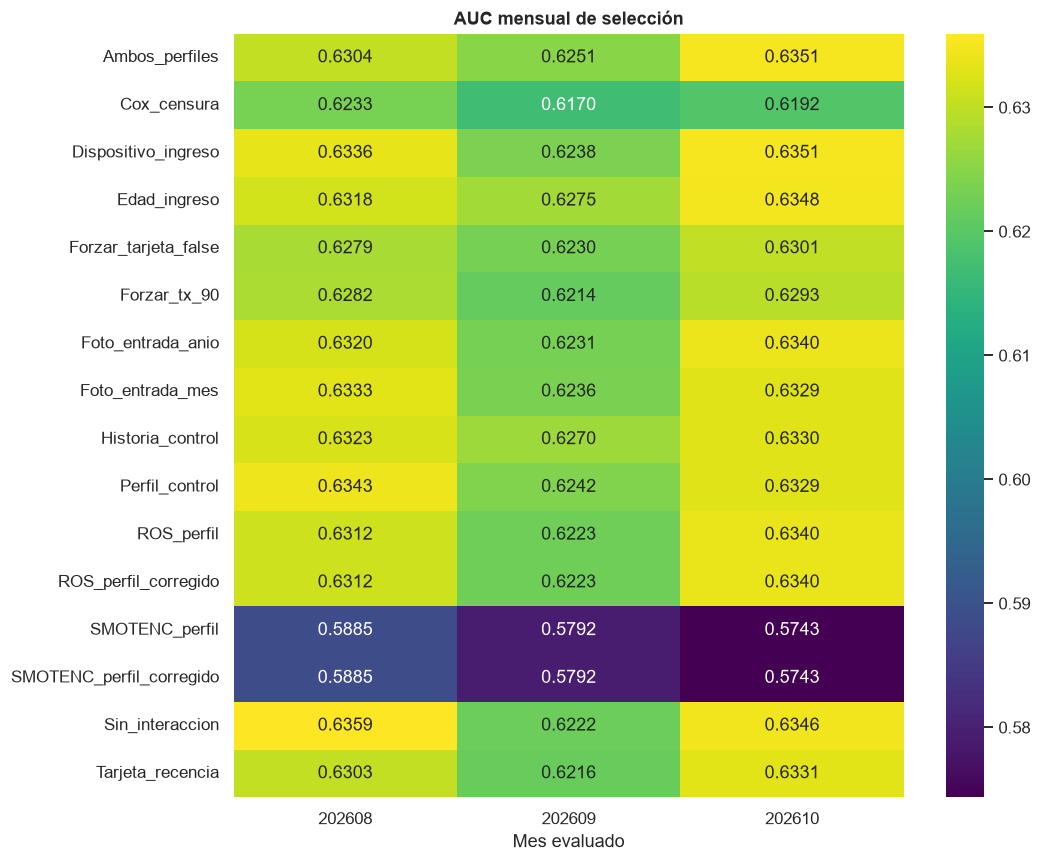

In [6]:
# Selección congelada: scores sobremuestreados brutos quedan solo como diagnóstico.
eligible=[n for n in backtest.modelo.unique() if n not in ['ROS_perfil','SMOTENC_perfil']]
means=backtest.loc[backtest.modelo.isin(eligible)].groupby('modelo')[['AUC','LogLoss','Brier']].mean().sort_values(['AUC','LogLoss'],ascending=[False,True])
chosen=means.index[0]
manifest=dict(chosen=chosen,selection_months=selection_months,specs=SPECS,
    criterio='AUC media ago-oct; desempate log-loss. Sin scores brutos sobremuestreados.',
    train_hash=hashlib.sha256((ROOT/'train.csv').read_bytes()).hexdigest(),
    source_hash=hashlib.sha256((HERE/'experimentos.py').read_bytes()).hexdigest())
(OUT/'seleccion_congelada.json').write_text(json.dumps(manifest,ensure_ascii=False,indent=2),encoding='utf-8')
means.to_csv(OUT/'comparacion_seleccion.csv')
print('DECISIÓN CONGELADA:',chosen)
display(means)
fig,ax=plt.subplots(figsize=(10,8))
sns.heatmap(backtest.pivot(index='modelo',columns='mes',values='AUC'),annot=True,fmt='.4f',cmap='viridis',ax=ax)
ax.set(title='AUC mensual de selección',xlabel='Mes evaluado',ylabel='')
plt.tight_layout(); plt.savefig(OUT/'01_backtest.png'); plt.show()

## 4. Noviembre: evaluación de la decisión ya congelada

Se muestran todas las alternativas para aprender, pero no se cambia la elección después de leer
noviembre. Un mejor score de un escenario contrafactual no demuestra que ese escenario sea real.

In [7]:
nov=d.loc[d.mes.eq(202611),['id_cliente','mes','objetivo','primera_obs']].reset_index(drop=True)
nov_rows=[]
for name,spec in SPECS.items():
    p,corr,detail=fit_month(d,groups,spec,202611)
    nov[name]=p
    nov_rows.append(dict(modelo=name,**scores(nov.objetivo,p)))
    if corr is not None:
        nov[name+'_corregido']=corr
        nov_rows.append(dict(modelo=name+'_corregido',**scores(nov.objetivo,corr)))
    print(f'Noviembre {name}: AUC={nov_rows[-1]["AUC"]:.4f}',flush=True)
p,detail=survival_cox(d,groups,202611)
nov['Cox_censura']=p
nov_rows.append(dict(modelo='Cox_censura',**scores(nov.objetivo,p)))
cox_details[202611]=detail
pd.DataFrame(cox_details).T.to_csv(OUT/'auditoria_cox.csv')
final=pd.DataFrame(nov_rows).set_index('modelo')
final['elegido_antes_de_noviembre']=final.index==chosen
display(final.sort_values('AUC',ascending=False))
final.to_csv(OUT/'metricas_noviembre.csv')
nov.to_csv(OUT/'predicciones_noviembre.csv',index=False)
# Incertidumbre pareada: una observación por cliente en este mes.
rng=np.random.default_rng(SEED)
y=nov.objetivo.to_numpy()
deltas=[]
for _ in range(600):
    idx=rng.integers(0,len(nov),len(nov))
    deltas.append(roc_auc_score(y[idx],nov[chosen].to_numpy()[idx])-roc_auc_score(y[idx],nov.Historia_control.to_numpy()[idx]))
ci=np.quantile(deltas,[.025,.5,.975])
display(pd.Series(ci,index=['p2.5','mediana','p97.5'],name='delta_AUC_vs_historia').to_frame())
pd.Series(ci,index=['p2.5','mediana','p97.5'],name='delta_AUC_vs_historia').to_csv(OUT/'bootstrap_pareado.csv')
segments=[]
for name in list(dict.fromkeys(['Historia_control',chosen])):
    for flag,label in [(1,'primera observación'),(0,'recurrente')]:
        z=nov.loc[nov.primera_obs.eq(flag)]
        segments.append(dict(modelo=name,segmento=label,**scores(z.objetivo,z[name])))
display(pd.DataFrame(segments))
pd.DataFrame(segments).to_csv(OUT/'segmentos_noviembre.csv',index=False)

Noviembre Perfil_control: AUC=0.6179


Noviembre Historia_control: AUC=0.6209


Noviembre Edad_ingreso: AUC=0.6198


Noviembre Dispositivo_ingreso: AUC=0.6179


Noviembre Ambos_perfiles: AUC=0.6195


...

Noviembre ROS_perfil: AUC=0.6155


Noviembre SMOTENC_perfil: AUC=0.5860


,AUC,Gini,LogLoss,Brier,AP,tasa,pred_media,n,elegido_antes_de_noviembre
modelo,,,,,,,,,
Historia_control,0.620884,0.241767,0.409864,0.124549,0.230134,0.151474,0.148031,9500,False
Foto_entrada_anio,0.619785,0.239570,0.410104,0.124619,0.228850,0.151474,0.147949,9500,False
Edad_ingreso,0.619754,0.239508,0.410118,0.124635,0.229435,0.151474,0.147165,9500,True
Ambos_perfiles,0.619511,0.239023,0.410222,0.124666,0.229244,0.151474,0.147515,9500,False
Tarjeta_recencia,0.619274,0.238547,0.410585,0.124769,0.226320,0.151474,0.147956,9500,False
Foto_entrada_mes,0.618251,0.236502,0.410033,0.124616,0.230139,0.151474,0.147088,9500,False
Perfil_control,0.617888,0.235776,0.410633,0.124795,0.227934,0.151474,0.138706,9500,False
Dispositivo_ingreso,0.617878,0.235756,0.410501,0.124700,0.227996,0.151474,0.146999,9500,False
Sin_interaccion,0.616701,0.233403,0.410151,0.124657,0.227639,0.151474,0.147697,9500,False


,delta_AUC_vs_historia
p2.5,-0.004733
mediana,-0.001164
p97.5,0.002528


,modelo,segmento,AUC,Gini,LogLoss,Brier,AP,tasa,pred_media,n
0,Historia_control,primera observación,0.601662,0.203323,0.487072,0.155081,0.280331,0.196429,0.175961,728
1,Historia_control,recurrente,0.620364,0.240728,0.403456,0.122016,0.225030,0.147743,0.145713,8772
2,Edad_ingreso,primera observación,0.601578,0.203156,0.487568,0.155155,0.279232,0.196429,0.175435,728
3,Edad_ingreso,recurrente,0.619198,0.238396,0.403691,0.122102,0.224346,0.147743,0.144819,8772


## 5. Sobremuestreo: ranking versus probabilidades

Balancear a 50/50 cambia el problema de probabilidad. La corrección usa exclusivamente el prior
original de entrenamiento; nunca ajusta al porcentaje positivo de noviembre. La equivalencia exacta
es un supuesto de cambio de prior, no una garantía de calibración después de SMOTENC.

,AUC,LogLoss,Brier,tasa,pred_media
modelo,,,,,
Perfil_control,0.617888,0.410633,0.124795,0.151474,0.138706
ROS_perfil,0.615526,0.624382,0.217923,0.151474,0.450405
ROS_perfil_corregido,0.615526,0.410922,0.124906,0.151474,0.135538
SMOTENC_perfil,0.586014,0.595436,0.206010,0.151474,0.384232
SMOTENC_perfil_corregido,0.586014,0.446730,0.131151,0.151474,0.120694


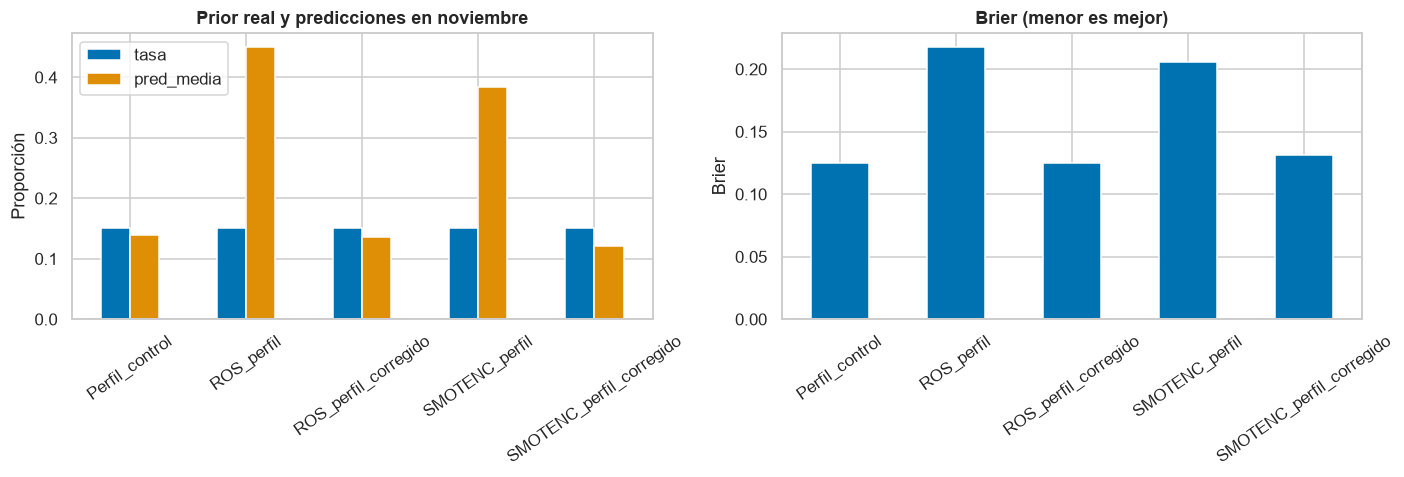

In [8]:
oversampling=final.loc[['Perfil_control','ROS_perfil','ROS_perfil_corregido',
                       'SMOTENC_perfil','SMOTENC_perfil_corregido'],['AUC','LogLoss','Brier','tasa','pred_media']]
display(oversampling)
fig,axes=plt.subplots(1,2,figsize=(13,4.5))
oversampling[['tasa','pred_media']].plot.bar(ax=axes[0])
axes[0].set(title='Prior real y predicciones en noviembre',ylabel='Proporción',xlabel='')
oversampling.Brier.plot.bar(ax=axes[1],color='#0072B2')
axes[1].set(title='Brier (menor es mejor)',ylabel='Brier',xlabel='')
for ax in axes: ax.tick_params(axis='x',rotation=35)
plt.tight_layout(); plt.savefig(OUT/'02_sobremuestreo.png'); plt.show()

## 6. Convertir alguna vez: qué podemos observar realmente

La etiqueta observable es **haber convertido hasta noviembre**, no convertir alguna vez en la vida.
Quienes no convirtieron siguen censurados. Primera observación por cliente y split aleatorio POR CLIENTE
70/30: diagnóstico retrospectivo, sin fuga de identidad, pero no validación temporal ni extrapolación.
Un control usa solo cohorte (equivalente a horizonte disponible) y otro fija la cohorte enero,
que tiene once meses de oportunidad para todos. No entran última fecha, duración final ni fin de trayectoria.

In [9]:
first=d.drop_duplicates('id_cliente').copy()
event=d.groupby('id_cliente').objetivo.max()
first['observado_hasta_nov']=first.id_cliente.map(event).astype(int)
cohorts=first.groupby('mes').observado_hasta_nov.agg(['size','mean'])
display(cohorts)
cohorts.to_csv(OUT/'tasas_por_cohorte.csv')
ever_rows=[]
idx_train,idx_val=train_test_split(np.arange(len(first)),test_size=.3,random_state=SEED,stratify=first.observado_hasta_nov)
for label,names in [('Perfil_sin_tiempo',groups['perfil']),('Solo_cohorte',['cohorte']),
                     ('Perfil_y_cohorte',groups['perfil']+['cohorte'])]:
    a,b=first.iloc[idx_train],first.iloc[idx_val]
    assert set(a.id_cliente).isdisjoint(set(b.id_cliente))
    model=cat_model(a[names]); model.fit(a[names],a.observado_hasta_nov)
    p=model.predict_proba(b[names])[:,1]
    ever_rows.append(dict(experimento=label,**scores(b.observado_hasta_nov,p)))
jan=first.loc[first.mes.eq(202601)].copy()
a,b=train_test_split(jan,test_size=.3,random_state=SEED,stratify=jan.observado_hasta_nov)
model=cat_model(a[groups['perfil']]); model.fit(a[groups['perfil']],a.observado_hasta_nov)
p=model.predict_proba(b[groups['perfil']])[:,1]
ever_rows.append(dict(experimento='Solo_enero_horizonte_11m',**scores(b.observado_hasta_nov,p)))
ever=pd.DataFrame(ever_rows)
display(ever)
ever.to_csv(OUT/'conversion_observada_sin_cuando.csv',index=False)

,size,mean
mes,,
202601,10400,0.811250
202602,921,0.781759
202603,2043,0.772394
202604,827,0.724305
202605,1973,0.680182
202606,1834,0.641767
202607,950,0.564211
202608,1760,0.494886
202609,1299,0.424942


,experimento,AUC,Gini,LogLoss,Brier,AP,tasa,pred_media,n
0,Perfil_sin_tiempo,0.705503,0.411007,0.570171,0.193940,0.825048,0.672757,0.675206,7389
1,Solo_cohorte,0.698078,0.396155,0.563769,0.189319,0.782229,0.672757,0.674151,7389
2,Perfil_y_cohorte,0.786415,0.572829,0.508479,0.168709,0.877324,0.672757,0.674647,7389
3,Solo_enero_horizonte_11m,0.708096,0.416191,0.429563,0.135010,0.911463,0.811218,0.809387,3120


## 7. Cuándo: evento en el primero, segundo o tercer mes

Una fila por entrada. Etiqueta multiclase: **0 = sin evento dentro de 3 meses**, **1/2/3 = intervalo
del evento**. La clase 0 no significa nunca. Se evalúan cohortes julio/agosto/septiembre con seguimiento
completo hasta septiembre/octubre/noviembre, respectivamente. Entrenamiento solo con cohortes cuyo
horizonte terminó ANTES de la entrada evaluada: abril/mayo/junio como máximas cohortes de entrenamiento.
Enero está truncado por la izquierda: sus tiempos son desde observación, no desde inicio real de riesgo.

Comparamos un clasificador binario del horizonte con uno multiclase. La suma de sus clases 1..3 da
probabilidad acumulada; clase 1 da la probabilidad del mes de entrada. El MAE de tiempo se reporta
solamente entre eventos ocurridos dentro del horizonte y con un baseline constante; no valida tiempos
de los censurados ni una predicción de por vida.

In [10]:
horizons=make_horizon(d)
horizon_rows,timing_rows=[],[]
for month in [202607,202608,202609]:
    a=make_horizon(d,label_end=month-1)
    b=horizons.loc[horizons.mes.eq(month)].copy()
    assert a.end_label.max()<month and set(a.id_cliente).isdisjoint(set(b.id_cliente))
    names=groups['perfil']
    binary=cat_model(a[names]); binary.fit(a[names],a.y_horizonte)
    p=binary.predict_proba(b[names])[:,1]
    horizon_rows.append(dict(modelo='Binario_3m',cohorte=month,ultima_cohorte_train=int(a.mes.max()),
                             n_train=len(a),**scores(b.y_horizonte,p)))
    multi=cat_model(a[names],multiclass=True); multi.fit(a[names],a.clase)
    assert np.array_equal(multi.classes_,[0,1,2,3])
    proba=multi.predict_proba(b[names])
    p_event=1-proba[:,0]
    horizon_rows.append(dict(modelo='Multiclase_3m',cohorte=month,ultima_cohorte_train=int(a.mes.max()),
                             n_train=len(a),**scores(b.y_horizonte,p_event)))
    conditional_time=proba[:,1:]@np.array([1,2,3])/np.maximum(p_event,1e-8)
    actual_events=b.clase.gt(0).to_numpy()
    # MAE se minimiza con mediana; comparar mediana condicional predicha y baseline train.
    cond=proba[:,1:]/np.maximum(p_event[:,None],1e-8)
    predicted_median=1+(np.cumsum(cond,axis=1)<.5).sum(axis=1)
    baseline_time=float(a.loc[a.clase.gt(0),'clase'].median())
    timing_rows.append(dict(cohorte=month,eventos_3m=int(actual_events.sum()),
        AUC_mes_entrada=roc_auc_score(b.clase.eq(1),proba[:,1]),
        MAE_mediana_modelo=mean_absolute_error(b.loc[actual_events,'clase'],predicted_median[actual_events]),
        MAE_mediana_constante=mean_absolute_error(b.loc[actual_events,'clase'],np.repeat(baseline_time,actual_events.sum())),
        media_tiempo_predicho_eventos=float(conditional_time[actual_events].mean())))
    print('Horizonte maduro terminado:',month,flush=True)
horizon_results=pd.DataFrame(horizon_rows)
timing_results=pd.DataFrame(timing_rows)
display(horizon_results); display(timing_results)
horizon_results.to_csv(OUT/'horizonte_3m.csv',index=False)
timing_results.to_csv(OUT/'tiempo_evento_3m.csv',index=False)

Horizonte maduro terminado: 202607


Horizonte maduro terminado: 202608


Horizonte maduro terminado: 202609


,modelo,cohorte,ultima_cohorte_train,n_train,AUC,Gini,LogLoss,Brier,AP,tasa,pred_media,n
0,Binario_3m,202607,202604,14191,0.673661,0.347323,0.614489,0.213455,0.589179,0.391579,0.389606,950
1,Multiclase_3m,202607,202604,14191,0.678415,0.356829,0.617988,0.214810,0.579646,0.391579,0.390793,950
2,Binario_3m,202608,202605,16164,0.656092,0.312183,0.634429,0.221602,0.595482,0.413636,0.395060,1760
3,Multiclase_3m,202608,202605,16164,0.658804,0.317609,0.635661,0.222221,0.596732,0.413636,0.394096,1760
4,Binario_3m,202609,202606,17998,0.668636,0.337272,0.631801,0.220972,0.620385,0.424942,0.394118,1299
5,Multiclase_3m,202609,202606,17998,0.659966,0.319932,0.635094,0.222499,0.617556,0.424942,0.392276,1299


,cohorte,eventos_3m,AUC_mes_entrada,MAE_mediana_modelo,MAE_mediana_constante,media_tiempo_predicho_eventos
0,202607,372,0.660760,0.680108,0.682796,1.879251
1,202608,728,0.633388,0.712912,0.717033,1.882098
2,202609,552,0.620942,0.668478,0.661232,1.878339


## 8. Síntesis de evidencia

Los scores acumulados y mensuales responden preguntas distintas. Mejorar AUC con un reloj ficticio
no demuestra que un mes sea un año; mejorar con una alteración no demuestra que el valor original
sea falso. Conservar todas las hipótesis y controles evita escoger una historia porque ajusta bien.
Los resultados de noviembre son exploratorios en un dataset ya utilizado muchas veces.

In [11]:
best=final.loc[chosen]
delta=best.AUC-final.loc['Historia_control','AUC']
summary=f'''# Resultado de la sesión experimental

Selección congelada con agosto-octubre: **{chosen}**.
Noviembre: AUC **{best.AUC:.4f}**, Gini **{best.Gini:.4f}**, log-loss **{best.LogLoss:.4f}**,
Brier **{best.Brier:.4f}**. Frente al control de historia: ΔAUC **{delta:+.4f}**,
IC pareado 95% **[{ci[0]:+.4f}, {ci[2]:+.4f}]**.

Se entrenaron trece variantes de CatBoost y un Cox, con tres ventanas de selección y noviembre;
se conservaron versiones crudas y corregidas de probabilidades sobremuestreadas. También se hicieron
cuatro diagnósticos de conversión observada y seis ajustes de horizonte maduro a tres meses.

No se entrenaron modelos con prehistorias inventadas seleccionadas por desenlace: agregarían
**{fake_events:,} ceros retrospectivos** solo a futuros conversores. Sus covariables antes de entrada
no se conocen y el criterio de inclusión utiliza su futuro. El diagnóstico cuantifica ese efecto.

Todas las inferencias de origen son hipótesis: puntuaciones de ingresos/edad no miden éxito;
dispositivo no mide gasto o ahorro; tarjeta vigente no garantiza uso y recencia general no es recencia
de tarjeta. El reloj anual tampoco corrige por sí mismo los valores congelados.

Para reproducir: ejecutar `python nuevas-tareas/ejecutar.py` con el entorno Python 3.13 del proyecto.
Los archivos anteriores permanecen intactos; no se cambió la entrega de diciembre.
'''
display(Markdown(summary))
(OUT/'resumen_ejecutado.md').write_text(summary,encoding='utf-8')

# Resultado de la sesión experimental

Selección congelada con agosto-octubre: **Edad_ingreso**.
Noviembre: AUC **0.6198**, Gini **0.2395**, log-loss **0.4101**,
Brier **0.1246**. Frente al control de historia: ΔAUC **-0.0011**,
IC pareado 95% **[-0.0047, +0.0025]**.

Se entrenaron trece variantes de CatBoost y un Cox, con tres ventanas de selección y noviembre;
se conservaron versiones crudas y corregidas de probabilidades sobremuestreadas. También se hicieron
cuatro diagnósticos de conversión observada y seis ajustes de horizonte maduro a tres meses.

No se entrenaron modelos con prehistorias inventadas seleccionadas por desenlace: agregarían
**37,593 ceros retrospectivos** solo a futuros conversores. Sus covariables antes de entrada
no se conocen y el criterio de inclusión utiliza su futuro. El diagnóstico cuantifica ese efecto.

Todas las inferencias de origen son hipótesis: puntuaciones de ingresos/edad no miden éxito;
dispositivo no mide gasto o ahorro; tarjeta vigente no garantiza uso y recencia general no es recencia
de tarjeta. El reloj anual tampoco corrige por sí mismo los valores congelados.

Para reproducir: ejecutar `python nuevas-tareas/ejecutar.py` con el entorno Python 3.13 del proyecto.
Los archivos anteriores permanecen intactos; no se cambió la entrega de diciembre.


1307